<a href="https://colab.research.google.com/github/bensonngi/Python_course_project/blob/main/Week6_Tidal_Turbine_Clustering_Analysis.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [3]:
from google.colab import files
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

uploaded = files.upload()

filename = next(iter(uploaded))
data = pd.read_csv(filename)

print("Dataset imported successfully!")
print("Number of rows:", data.shape[0])
print("Number of columns:", data.shape[1])

data.head()

Saving synthetic_tidal_turbine_dataset.csv to synthetic_tidal_turbine_dataset.csv
Dataset imported successfully!
Number of rows: 243
Number of columns: 7


,Velocity_m_s,TSR,Rotor_RPM,Angular_Velocity_rad_s,Torque_Nm,Power_W,Cp
0,1.0,1.50,2.86,0.30,2623.07,786.92,0.0200
1,1.0,1.75,3.34,0.35,2848.52,996.98,0.0253
2,1.0,2.00,3.82,0.40,3866.09,1546.43,0.0393
3,1.0,2.25,4.30,0.45,5123.50,2305.57,0.0586
4,1.0,2.50,4.77,0.50,6590.68,3295.34,0.0838


Three numerical variables were selected for clustering: tidal flow velocity, tip-speed ratio (TSR), and power coefficient (\(C_p\)).

These variables represent different aspects of tidal turbine operation. Flow velocity describes the speed of the incoming tidal current, while TSR describes the rotational operating condition of the turbine. The power coefficient indicates the turbine's ability to extract energy from the available tidal flow.

The objective is to identify groups of operating cases that have similar characteristics based on these three variables. Unlike supervised learning, clustering does not require a predefined target variable because the algorithm identifies patterns and groups directly from the data.

In [4]:
# Select the variables for clustering
X = data[["Velocity_m_s", "TSR", "Cp"]]

print("Selected clustering features:")
display(X.head())

print("\nDataset shape:", X.shape)

Selected clustering features:


,Velocity_m_s,TSR,Cp
0,1.0,1.50,0.0200
1,1.0,1.75,0.0253
2,1.0,2.00,0.0393
3,1.0,2.25,0.0586
4,1.0,2.50,0.0838



Dataset shape: (243, 3)


Before applying K-Means clustering, the selected features were standardized using StandardScaler. This was necessary because the variables have different numerical ranges and units.

K-Means uses distance measurements to group similar observations. Without scaling, variables with larger numerical values could have a greater influence on the clustering results. Standardization ensures that flow velocity, TSR, and the power coefficient contribute more comparably to the distance calculations.

In [5]:
from sklearn.preprocessing import StandardScaler

# Create the scaler
scaler = StandardScaler()

# Standardize the selected features
X_scaled = scaler.fit_transform(X)

print("Features standardized successfully!")

# Display the standardized data
scaled_data = pd.DataFrame(
    X_scaled,
    columns=X.columns
)

display(scaled_data.head())

Features standardized successfully!


,Velocity_m_s,TSR,Cp
0,-1.549193,-1.669046,-1.364356
1,-1.549193,-1.540658,-1.329792
2,-1.549193,-1.412270,-1.238492
3,-1.549193,-1.283881,-1.112628
4,-1.549193,-1.155493,-0.948288


In [6]:
from sklearn.cluster import KMeans

# Apply K-Means with 3 clusters initially
kmeans = KMeans(
    n_clusters=3,
    random_state=42,
    n_init=10
)

# Train the clustering model
clusters = kmeans.fit_predict(X_scaled)

print("K-Means clustering completed!")

K-Means clustering completed!


In [7]:
data["Cluster"] = clusters

print("Cluster assignments:")
display(data.head(10))

Cluster assignments:


,Velocity_m_s,TSR,Rotor_RPM,Angular_Velocity_rad_s,Torque_Nm,Power_W,Cp,Cluster
0,1.0,1.50,2.86,0.30,2623.07,786.92,0.0200,1
1,1.0,1.75,3.34,0.35,2848.52,996.98,0.0253,1
2,1.0,2.00,3.82,0.40,3866.09,1546.43,0.0393,1
3,1.0,2.25,4.30,0.45,5123.50,2305.57,0.0586,1
4,1.0,2.50,4.77,0.50,6590.68,3295.34,0.0838,1
5,1.0,2.75,5.25,0.55,8222.17,4522.19,0.1149,1
6,1.0,3.00,5.73,0.60,9979.36,5987.62,0.1522,1
7,1.0,3.25,6.21,0.65,11836.82,7693.93,0.1955,1
8,1.0,3.50,6.68,0.70,13755.70,9628.99,0.2447,1
9,1.0,3.75,7.16,0.75,15636.62,11727.47,0.2981,0


The assignment requires us to explore different numbers of clusters and select an appropriate number.

We will use two methods:
1. The Elbow Method.
2. The Silhouette Score.

A. The Elbow Method
The Elbow Method helps us determine a suitable number of clusters by examining how the within-cluster sum of squared distances (inertia) changes as the number of clusters increases.

Generally, adding more clusters reduces inertia. However, at some point, the improvement becomes smaller.

We look for the point where the curve begins to bend, forming an elbow.

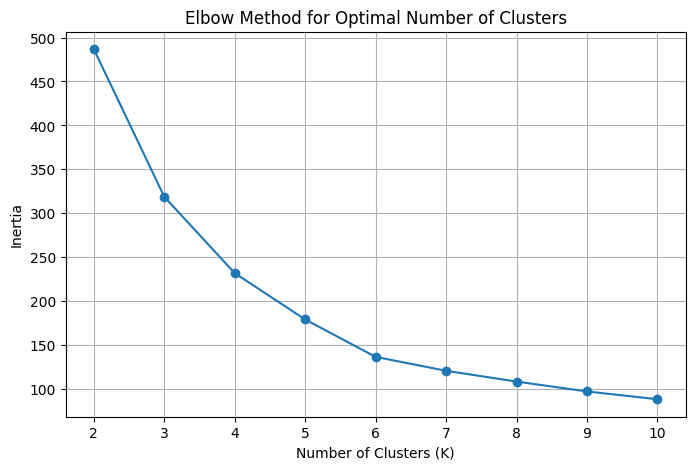

In [8]:
inertia_values = []

# Test different numbers of clusters
for k in range(2, 11):

    model = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    model.fit(X_scaled)

    inertia_values.append(model.inertia_)

# Plot the Elbow curve
plt.figure(figsize=(8, 5))

plt.plot(
    range(2, 11),
    inertia_values,
    marker="o"
)

plt.xlabel("Number of Clusters (K)")
plt.ylabel("Inertia")
plt.title("Elbow Method for Optimal Number of Clusters")
plt.xticks(range(2, 11))
plt.grid(True)

plt.show()

B. Silhouette Score
We will use another measure to support our decision.

The Silhouette Score measures how well an observation fits within its assigned cluster compared with other clusters.

Its values range from −1 to +1.
Score	Interpretation
Close to +1	Observations are well grouped
Around 0	Clusters may overlap
Negative	Some observations may be assigned to inappropriate clusters

In [9]:
from sklearn.metrics import silhouette_score
from sklearn.cluster import KMeans

silhouette_values = []

for k in range(2, 11):

    model = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    labels = model.fit_predict(X_scaled)

    score = silhouette_score(X_scaled, labels)

    silhouette_values.append(score)

# Display the results
silhouette_results = pd.DataFrame({
    "Number of Clusters": range(2, 11),
    "Silhouette Score": silhouette_values
})

display(silhouette_results.round(4))

,Number of Clusters,Silhouette Score
0,2,0.3425
1,3,0.4102
2,4,0.3973
3,5,0.4017
4,6,0.4130
5,7,0.3809
6,8,0.3741
7,9,0.3702
8,10,0.3533


Now visualize the results:

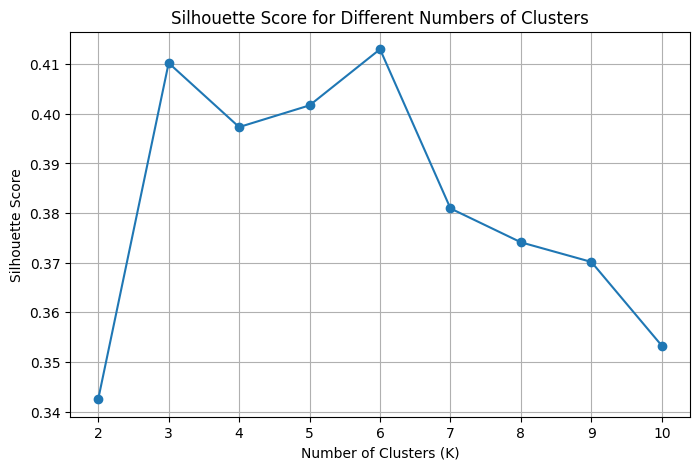

In [10]:
plt.figure(figsize=(8, 5))

plt.plot(
    range(2, 11),
    silhouette_values,
    marker="o"
)

plt.xlabel("Number of Clusters (K)")
plt.ylabel("Silhouette Score")
plt.title("Silhouette Score for Different Numbers of Clusters")
plt.xticks(range(2, 11))
plt.grid(True)

plt.show()

How do we select the final number of clusters?
We consider both graphs:
- The Elbow Method helps identify a point where additional clusters provide diminishing improvements.
- The Silhouette Score helps assess how well separated the groups are.
A higher silhouette score is generally preferable, but we should also consider whether the resulting groups are meaningful for our tidal turbine project.

Do not automatically choose three clusters just because we initially used three. We will use the results of these two methods to make our final decision.

In [11]:
# Select the number of clusters based on your analysis
optimal_k = 3  # Change this if your analysis suggests another value

final_kmeans = KMeans(
    n_clusters=optimal_k,
    random_state=42,
    n_init=10
)

# Fit the final model
final_clusters = final_kmeans.fit_predict(X_scaled)

# Add cluster labels to the original data
data["Cluster"] = final_clusters

print("Final clustering completed!")
print("Number of clusters:", optimal_k)

display(data.head())

Final clustering completed!
Number of clusters: 3


,Velocity_m_s,TSR,Rotor_RPM,Angular_Velocity_rad_s,Torque_Nm,Power_W,Cp,Cluster
0,1.0,1.50,2.86,0.30,2623.07,786.92,0.0200,1
1,1.0,1.75,3.34,0.35,2848.52,996.98,0.0253,1
2,1.0,2.00,3.82,0.40,3866.09,1546.43,0.0393,1
3,1.0,2.25,4.30,0.45,5123.50,2305.57,0.0586,1
4,1.0,2.50,4.77,0.50,6590.68,3295.34,0.0838,1


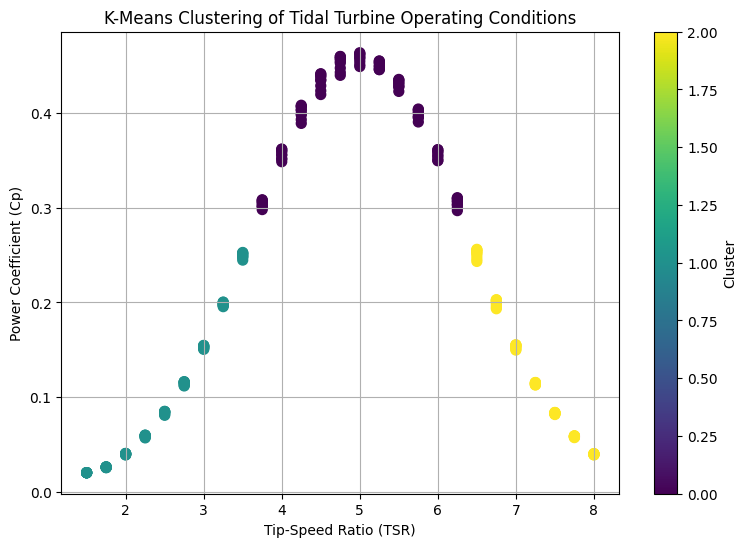

In [12]:
plt.figure(figsize=(9, 6))

plt.scatter(
    data["TSR"],
    data["Cp"],
    c=data["Cluster"],
    cmap="viridis",
    s=50
)

plt.xlabel("Tip-Speed Ratio (TSR)")
plt.ylabel("Power Coefficient (Cp)")
plt.title("K-Means Clustering of Tidal Turbine Operating Conditions")

plt.colorbar(label="Cluster")
plt.grid(True)

plt.show()

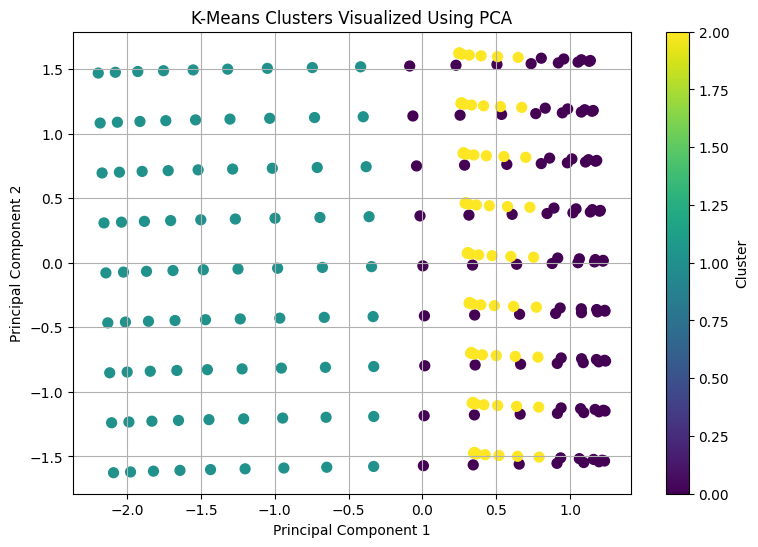

Total variance represented: 72.43 %


In [13]:
from sklearn.decomposition import PCA

pca = PCA(n_components=2)

X_pca = pca.fit_transform(X_scaled)

plt.figure(figsize=(9, 6))

plt.scatter(
    X_pca[:, 0],
    X_pca[:, 1],
    c=data["Cluster"],
    cmap="viridis",
    s=50
)

plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.title("K-Means Clusters Visualized Using PCA")

plt.colorbar(label="Cluster")
plt.grid(True)

plt.show()

print(
    "Total variance represented:",
    round(sum(pca.explained_variance_ratio_) * 100, 2),
    "%"
)

In [14]:
# Calculate average values for each cluster
cluster_summary = data.groupby("Cluster").agg({
    "Velocity_m_s": ["mean", "min", "max"],
    "TSR": ["mean", "min", "max"],
    "Cp": ["mean", "min", "max"],
    "Cp": ["mean", "min", "max"]
})

display(cluster_summary.round(4))

Velocity_m_s             TSR                  Cp                
                mean  min  max  mean   min   max    mean     min     max
Cluster                                                                 
0                2.0  1.0  3.0  5.00  3.75  6.25  0.3952  0.2970  0.4639
1                2.0  1.0  3.0  2.50  1.50  3.50  0.1047  0.0200  0.2528
2                2.0  1.0  3.0  7.25  6.50  8.00  0.1284  0.0388  0.2561

In [15]:
cluster_sizes = data["Cluster"].value_counts().sort_index()

print("Number of operating cases in each cluster:")
display(cluster_sizes)

Number of operating cases in each cluster:


,count
Cluster,
0,99
1,81
2,63


### Discussion of Clustering Results

K-Means clustering was applied to the synthetic tidal turbine dataset to identify groups of operating conditions with similar characteristics. Three numerical variables, flow velocity, tip-speed ratio, and power coefficient, were selected for the analysis. The features were standardized before clustering to ensure that differences in their numerical scales did not disproportionately influence the distance calculations.

The appropriate number of clusters was investigated using the Elbow Method and Silhouette Score. These methods were used to examine the within-cluster variation and the separation between the identified groups.

The resulting clusters represent different combinations of tidal flow velocity, tip-speed ratio, and power coefficient. By examining the average values of these variables within each group, it is possible to identify differences in turbine operating conditions and associated performance.

The groups may represent different operating regions of the tidal turbine, including conditions associated with relatively low, intermediate, and high power coefficients. These groupings can help improve understanding of how operating conditions relate to turbine performance and may provide useful insights for identifying favourable operating regions.

Since the dataset is synthetic and based on simplified turbine equations, the identified clusters represent patterns in the generated data rather than experimentally verified operating regimes of a real tidal turbine.

### Conclusion

This assignment demonstrated the application of unsupervised machine learning using K-Means clustering to analyse synthetic tidal turbine operating data. Flow velocity, tip-speed ratio, and power coefficient were selected as clustering features and standardized before applying the algorithm.

Different numbers of clusters were investigated using the Elbow Method and Silhouette Score to identify an appropriate grouping. The resulting clusters provided a way to explore similarities and differences among turbine operating cases without using a predefined target variable.

The analysis demonstrates how clustering can be used to identify operating regions with different characteristics and potentially support tidal turbine performance analysis and optimization. Further investigation using experimental or CFD simulation data would be necessary to determine whether similar operating groups exist in actual tidal turbine systems.